In [1]:
import gymnasium as gym

# Setting up the environment

In [2]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

env = RacetrackEnv(True, soft_reset=True)
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0

results = {
    "crashed" : 0,
    "list_of_steps": []  
}
number_of_steps = 0
while episodes != 100:
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    number_of_steps += 1
    total_reward += reward
    done = terminated or truncated
    # # Uncomment to get a visual of the car traveling
    # clear_output(wait=True)
    # sleep(1)
    # print(env.render())
    if info["crashed"]:
        results["crashed"] += 1
    if done:
        results["list_of_steps"].append(number_of_steps)
        number_of_steps = 0
        if episodes % 10 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print(f"Number of crashes: {results['crashed']}. Average number of steps {sum(results['list_of_steps'])/len(results['list_of_steps'])}")

Finished iteration 0
Finished iteration 10
Finished iteration 20
Finished iteration 30
Finished iteration 40
Finished iteration 50
Finished iteration 60
Finished iteration 70
Finished iteration 80
Finished iteration 90
Number of crashes: 36136. Average number of steps 2255.36


In [3]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

env = RacetrackEnv(True, soft_reset=False)
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0

results = {
    "crashed" : 0,
    "list_of_steps": []  
}
number_of_steps = 0
while episodes != 100:
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    number_of_steps += 1
    total_reward += reward
    done = terminated or truncated
    # # Uncomment to get a visual of the car traveling
    # clear_output(wait=True)
    # sleep(1)
    # print(env.render())
    if info["crashed"]:
        results["crashed"] += 1
    if done:
        results["list_of_steps"].append(number_of_steps)
        number_of_steps = 0
        if episodes % 10 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print(f"Number of crashes: {results['crashed']}. Average number of steps {sum(results['list_of_steps'])/len(results['list_of_steps'])}")

Finished iteration 0
Finished iteration 10
Finished iteration 20
Finished iteration 30
Finished iteration 40
Finished iteration 50
Finished iteration 60
Finished iteration 70
Finished iteration 80
Finished iteration 90
Number of crashes: 100. Average number of steps 6.46


# Solving Markov Decision Problems via Monte Carlo & SARSA

In [4]:
class agent_monte_carlo:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.n_map = {}
        self.q_map = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,trajectory):
        """
        First-visit Monte Carlo update.
        trajectory is stored as (x, y, vx, vy, action, reward), where reward is
        the reward received for taking action in that state
        """
        T = len(trajectory)
        y_discount = self.config["discount"]

        # Index of the first time each (s, a) pair shows up in the episode
        first_visit = {}
        for t in range(T):
            state_action_pair = (trajectory[t][:4], trajectory[t][4])
            if state_action_pair not in first_visit:
                first_visit[state_action_pair] = t

        G = 0
        for t in reversed(range(T)):
            s_t = trajectory[t][:4]
            a_t = trajectory[t][4]
            r_t = trajectory[t][5]
            G = r_t + y_discount*G

            state_action_pair = (s_t, a_t)
            if first_visit[state_action_pair] == t:
                # Incremental average of the returns, so we don't store every G
                n = self.n_map.get(state_action_pair, 0) + 1
                self.n_map[state_action_pair] = n
                q = self.q_map.get(state_action_pair, 0.0)
                self.q_map[state_action_pair] = q + (G - q) / n
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        n_actions = 9
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [5]:
# Run this cell to reload the python file!!
import importlib
import racetrack

importlib.reload(racetrack)
from racetrack import RacetrackEnv

In [10]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


def monte_carlo_env(mc_class, provided_reward, training = True, episodes_max = 2000, agent = None, label = ""):
    if agent is None:
        assert mc_class is not None
        agent = mc_class({
            "discount": 0.9
        })
    track_env = RacetrackEnv(provided_reward, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)

    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)

    while episodes != episodes_max:
        if episodes % 100 == 0:
            print(f"{label}Episode {episodes}")

        track_env.reset()
        trajectory = []
        done = False
        total_episode_reward = 0

        while not done:
            x, y = track_env.pos
            vx, vy = track_env.vel
            state = (x, y, vx, vy)
            visits[y, x] += 1

            action = agent.pi(state, epsilon)

            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward

            if info.get("crashed", False):
                episode_results["crashed"] += 1

            # Record the step into the trajectory list
            trajectory.append((x, y, vx, vy, action, reward))

        if training:
            agent.update_Q(trajectory)

        # Record metrics at the end of the episode
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)

        episode_results["rewards"].append(total_episode_reward)
        episodes += 1

    print(f"{label}Training finished!")
    return agent, visits, episode_results, track_env

In [11]:
mc_agent, visits, episode_results, track_env = monte_carlo_env(agent_monte_carlo, True)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


In [12]:
def print_episode_results(results):
    print(f"crashed: {results['crashed']}")
    print(f"average_episode_length: {sum(results['list_of_steps'])/len(results['list_of_steps'])}")
    print(f"average_reward: {sum(results['rewards'])/len(results['rewards'])}")
def plot_heatmap(cells_visited, track_environment, title = "Racetrack: visited positions over training episodes"):
    mask = ~track_environment.track
    fig, ax = plt.subplots(figsize=(14, 15))
    sns.heatmap(
        cells_visited.astype(float),
        mask=mask,
        cmap="Blues",
        annot=True,
        fmt=".0f",
        annot_kws={"size": 5},
        cbar_kws={"label": "Visit count"},
        linewidths=0.1,
        linecolor="white",
        square=True,
        ax=ax,
    )
    ax.set_facecolor("#e5e5e5")
    ax.invert_yaxis()
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

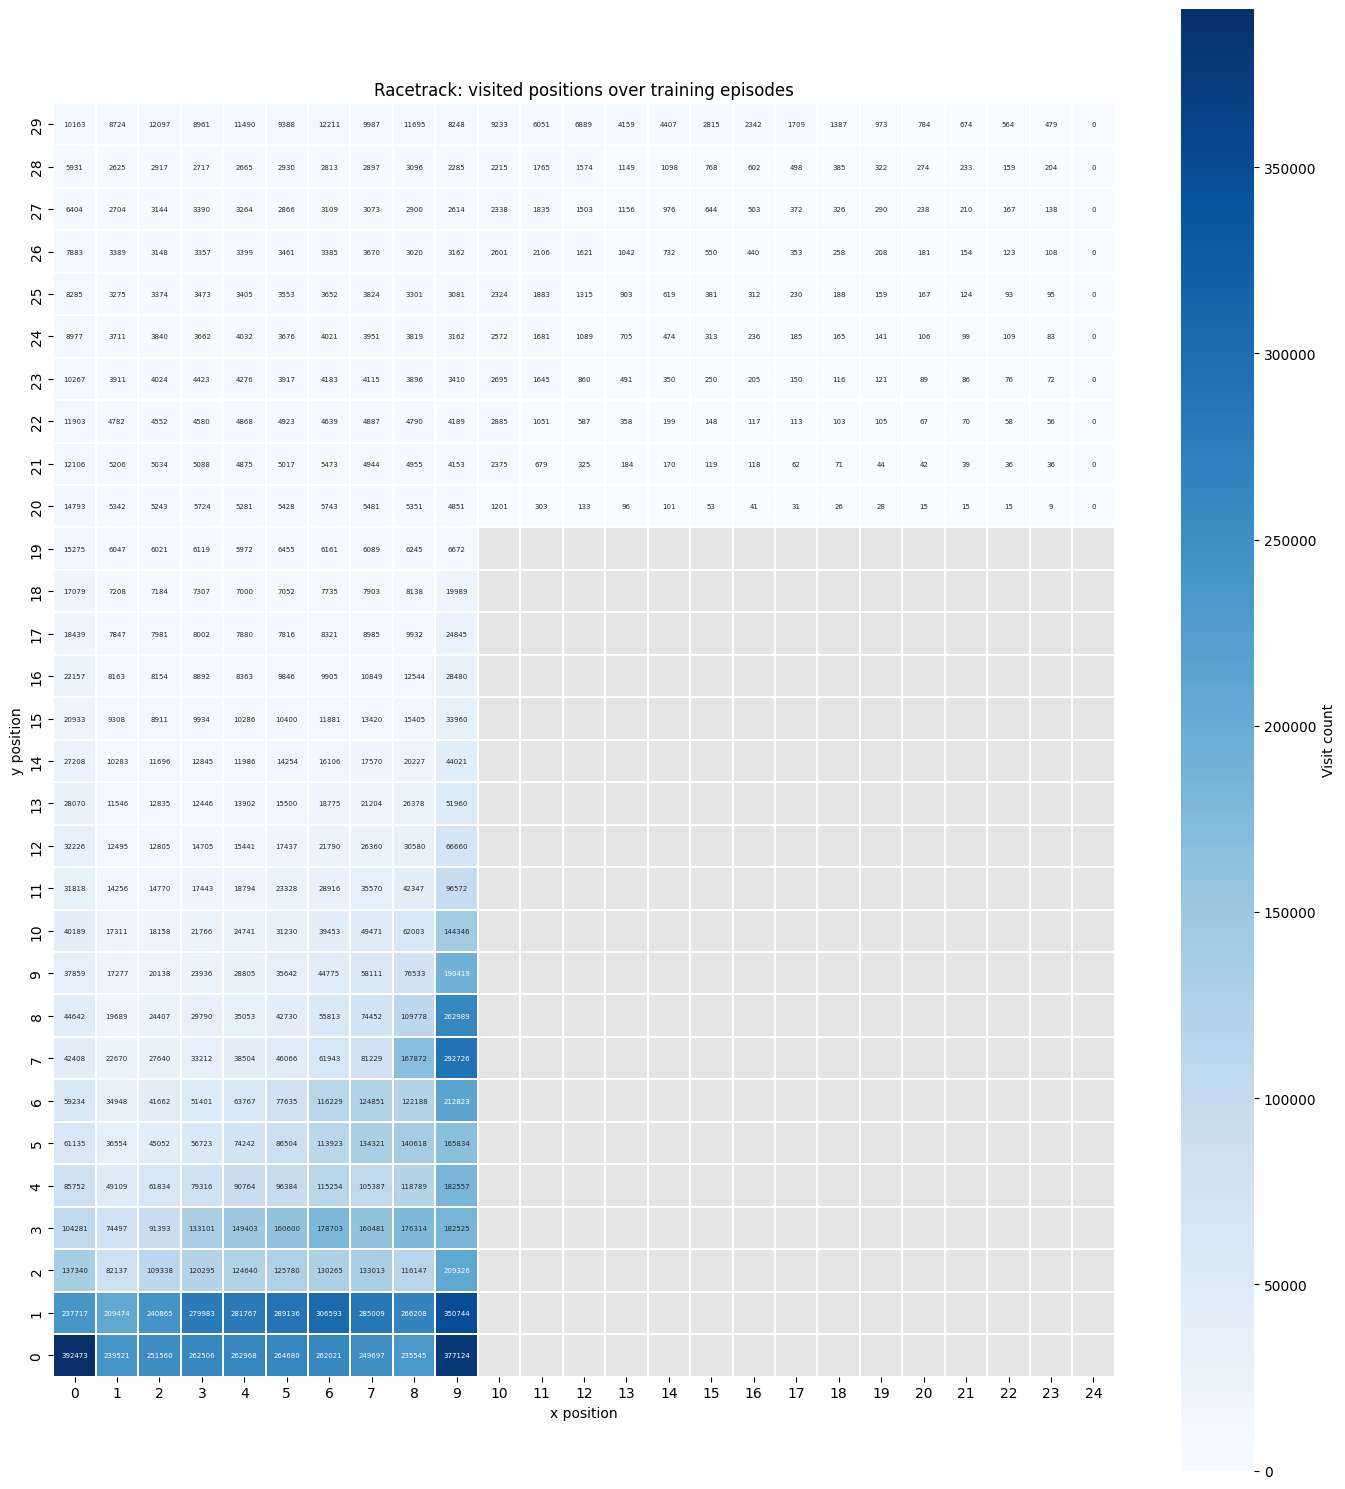

crashed: 2412857
average_episode_length: 7843.678
average_reward: 557.2607007135664


In [13]:
plot_heatmap(visits, track_env)
print_episode_results(episode_results)

In [14]:
import numpy as np

class agent_sarsa:
    '''A class to manage the agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]

    def update_Q(self, trajectory, done):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        state_prime = trajectory[:4]
        action_prime = trajectory[4]
        reward = trajectory[5]
        
        state_action_pair = (self.current_state, self.current_action)
        state_action_prime_pair = (state_prime, action_prime)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]

        q_map_value = self.q_map.get(state_action_pair, 0)
        if done:
            q_map_prime_value = 0
        else:
            state_action_prime_pair = (state_prime, action_prime)
            q_map_prime_value = self.q_map.get(state_action_prime_pair, 0)
        
        self.q_map[state_action_pair] = q_map_value + alpha * (reward + y_discount * q_map_prime_value - q_map_value)
        
        self.current_state = state_prime
        self.current_action = action_prime

    def pi(self, state, epsilon):
        n_actions = self.config.get("n_actions", 9)
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [15]:
import numpy as np
# Had Claude generate this class based off of my other sarsa class
class agent_expected_sarsa:
    '''A class to manage the Expected SARSA agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying hyperparameters and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]
        # Epsilon of the policy being followed, updated every time pi() is called
        self.epsilon = config.get("epsilon", 0.0)

    def get_probabilities(self, state, epsilon):

        n_actions = self.config.get("n_actions", 9)
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        for ba in best_actions:
            probs[ba] += (1.0 - epsilon) / len(best_actions)
            
        return probs

    def update_Q(self, step_data, done):
        """
        Performs the Expected SARSA step-by-step update.
        step_data is stored as (next_x, next_y, next_vx, next_vy, next_action, reward)
        """
        state_prime = step_data[:4]
        action_prime = step_data[4]
        reward = step_data[5]
        
        state_action_pair = (self.current_state, self.current_action)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]
        n_actions = self.config.get("n_actions", 9)

        q_map_value = self.q_map.get(state_action_pair, 0.0)
        
        if done:
            expected_next_q = 0.0
        else:
            probs = self.get_probabilities(state_prime, self.epsilon)
            next_action_values = [self.q_map.get((state_prime, a), 0.0) for a in range(n_actions)]
            expected_next_q = np.sum(probs * np.array(next_action_values))
        
        target = reward + y_discount * expected_next_q
        self.q_map[state_action_pair] = q_map_value + alpha * (target - q_map_value)
        
        self.current_state = state_prime
        self.current_action = action_prime

    def pi(self, state, epsilon):
        """
        Selects an action using the epsilon-greedy probability distribution.
        """
        self.epsilon = epsilon
        n_actions = self.config.get("n_actions", 9)
        probs = self.get_probabilities(state, epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [16]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


def sarsa_env(sarsa_class, provided_reward, training = True, episodes_max = 2000, agent = None, label = ""):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            "state": (0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    track_env = RacetrackEnv(provided_reward, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.2
        elif episodes >= episodes_max*0.6:
            epsilon = 0.5
        elif episodes >= episodes_max*0.4:
            epsilon = 0.7
            
        if episodes % 100 == 0:
            print(f"{label}Episode {episodes}")
            
        obs, info = track_env.reset()
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        
        action = agent.pi(state, epsilon)
        
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward
            
            next_x, next_y = track_env.pos
            next_vx, next_vy = track_env.vel
            next_state = (next_x, next_y, next_vx, next_vy)
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0 
                
            step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
            action = next_action
            x, y, vx, vy = next_x, next_y, next_vx, next_vy
    
        # Record metrics at the end of the episode
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print(f"{label}Training finished!")
    return agent, visits, episode_results, track_env


In [19]:
expected_sarsa_agent, expected_sarsa_visits, expected_sarsa_results, expected_sarsa_track_env = sarsa_env(agent_expected_sarsa, True)

In [20]:
plot_heatmap(expected_sarsa_visits, expected_sarsa_track_env)
print_episode_results(expected_sarsa_results)

NameError: name 'expected_sarsa_visits' is not defined

In [24]:
expected_sarsa_my_reward_agent, expected_sarsa_my_reward_visits, expected_sarsa_my_reward_results, expected_sarsa_my_reward_track_env = sarsa_env(agent_expected_sarsa, False, episodes_max = 4500)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Episode 2000
Episode 2100
Episode 2200
Episode 2300
Episode 2400
Episode 2500
Episode 2600
Episode 2700
Episode 2800
Episode 2900
Episode 3000
Episode 3100
Episode 3200
Episode 3300
Episode 3400
Episode 3500
Episode 3600
Episode 3700
Episode 3800
Episode 3900
Episode 4000
Episode 4100
Episode 4200
Episode 4300
Episode 4400
Training finished!


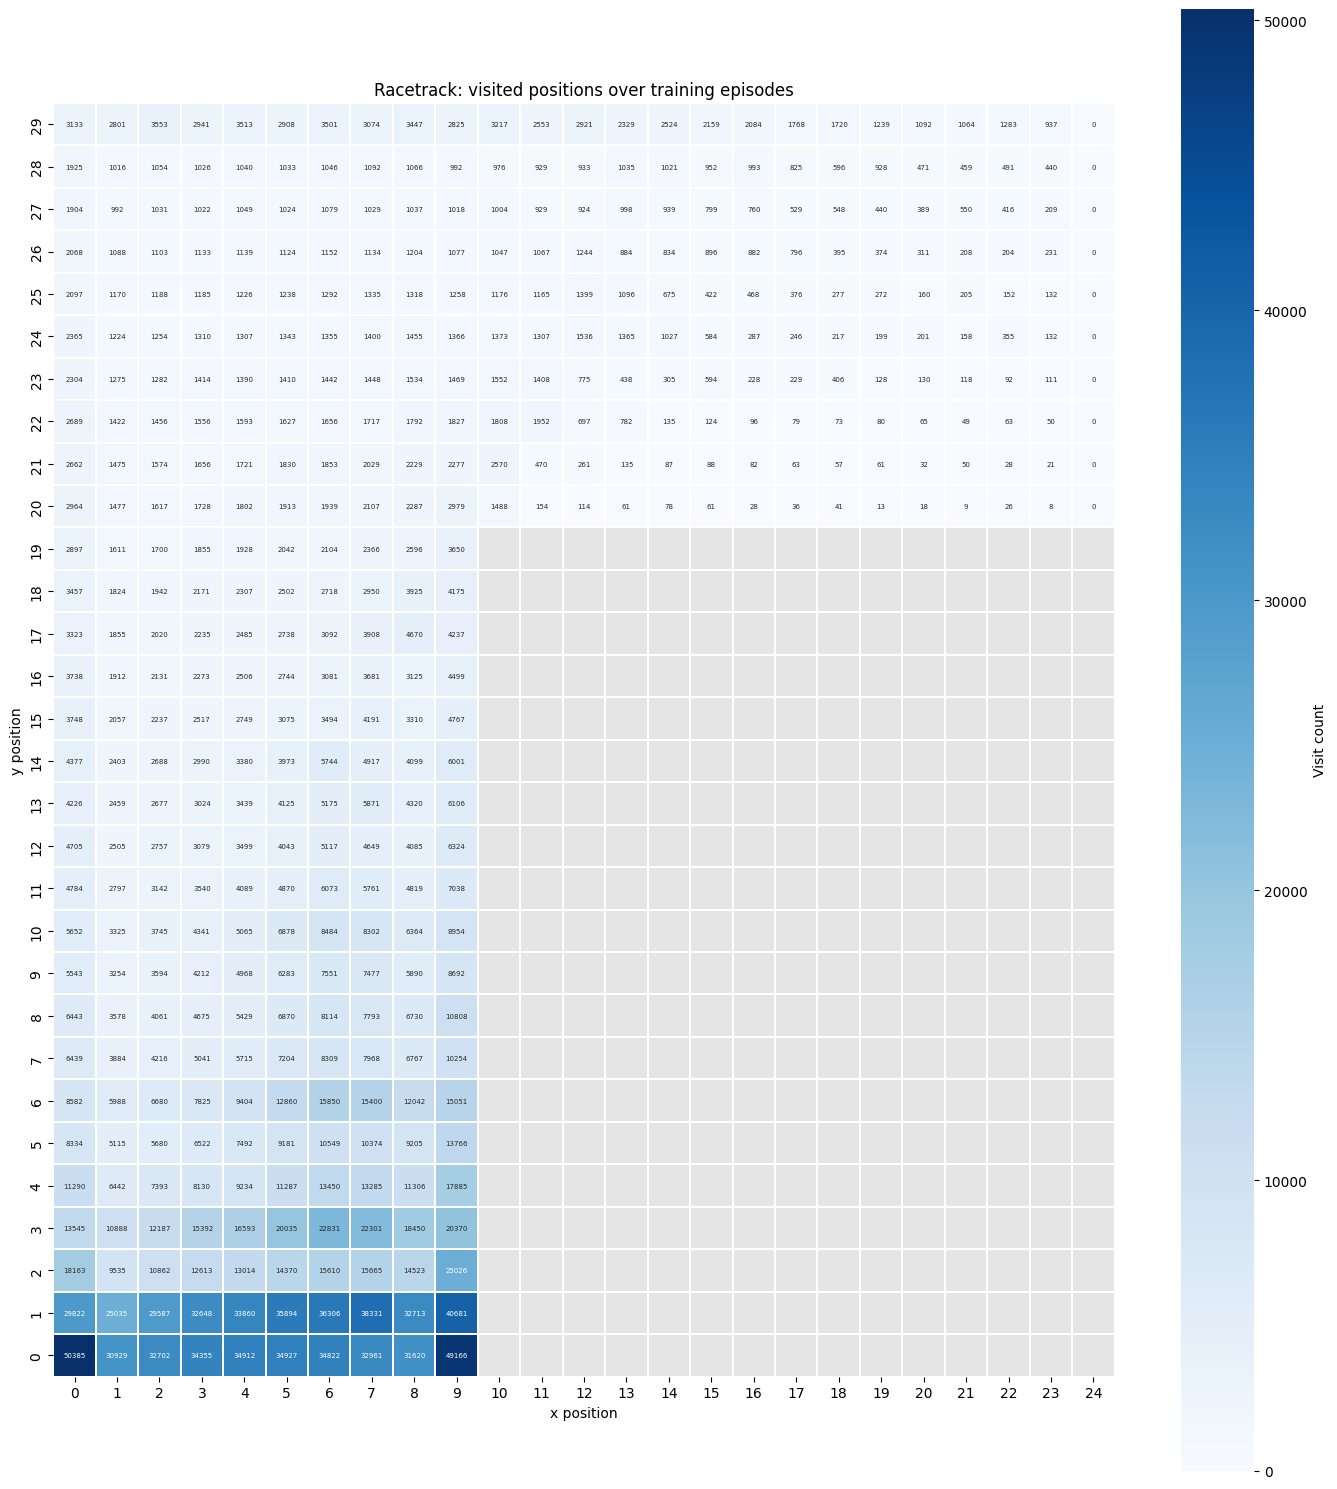

crashed: 294156
average_episode_length: 477.73488888888886
average_reward: -230.1674888888897


In [25]:
plot_heatmap(expected_sarsa_my_reward_visits, expected_sarsa_my_reward_track_env)
print_episode_results(expected_sarsa_my_reward_results)

In [ ]:
sarsa_agent, sarsa_visits, sarsa_results, sarsa_track_env = sarsa_env(agent_sarsa, True, episodes_max = 4500)

In [ ]:
plot_heatmap(sarsa_visits, sarsa_track_env)
print_episode_results(sarsa_results)

In [26]:
sarsa_my_reward_agent, sarsa_my_reward_visits, sarsa_my_reward_results, sarsa_my_reward_track_env = sarsa_env(agent_sarsa, False, episodes_max = 4500)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Episode 2000
Episode 2100
Episode 2200
Episode 2300
Episode 2400
Episode 2500
Episode 2600
Episode 2700
Episode 2800
Episode 2900
Episode 3000
Episode 3100
Episode 3200
Episode 3300
Episode 3400
Episode 3500
Episode 3600
Episode 3700
Episode 3800
Episode 3900
Episode 4000
Episode 4100
Episode 4200
Episode 4300
Episode 4400
Training finished!


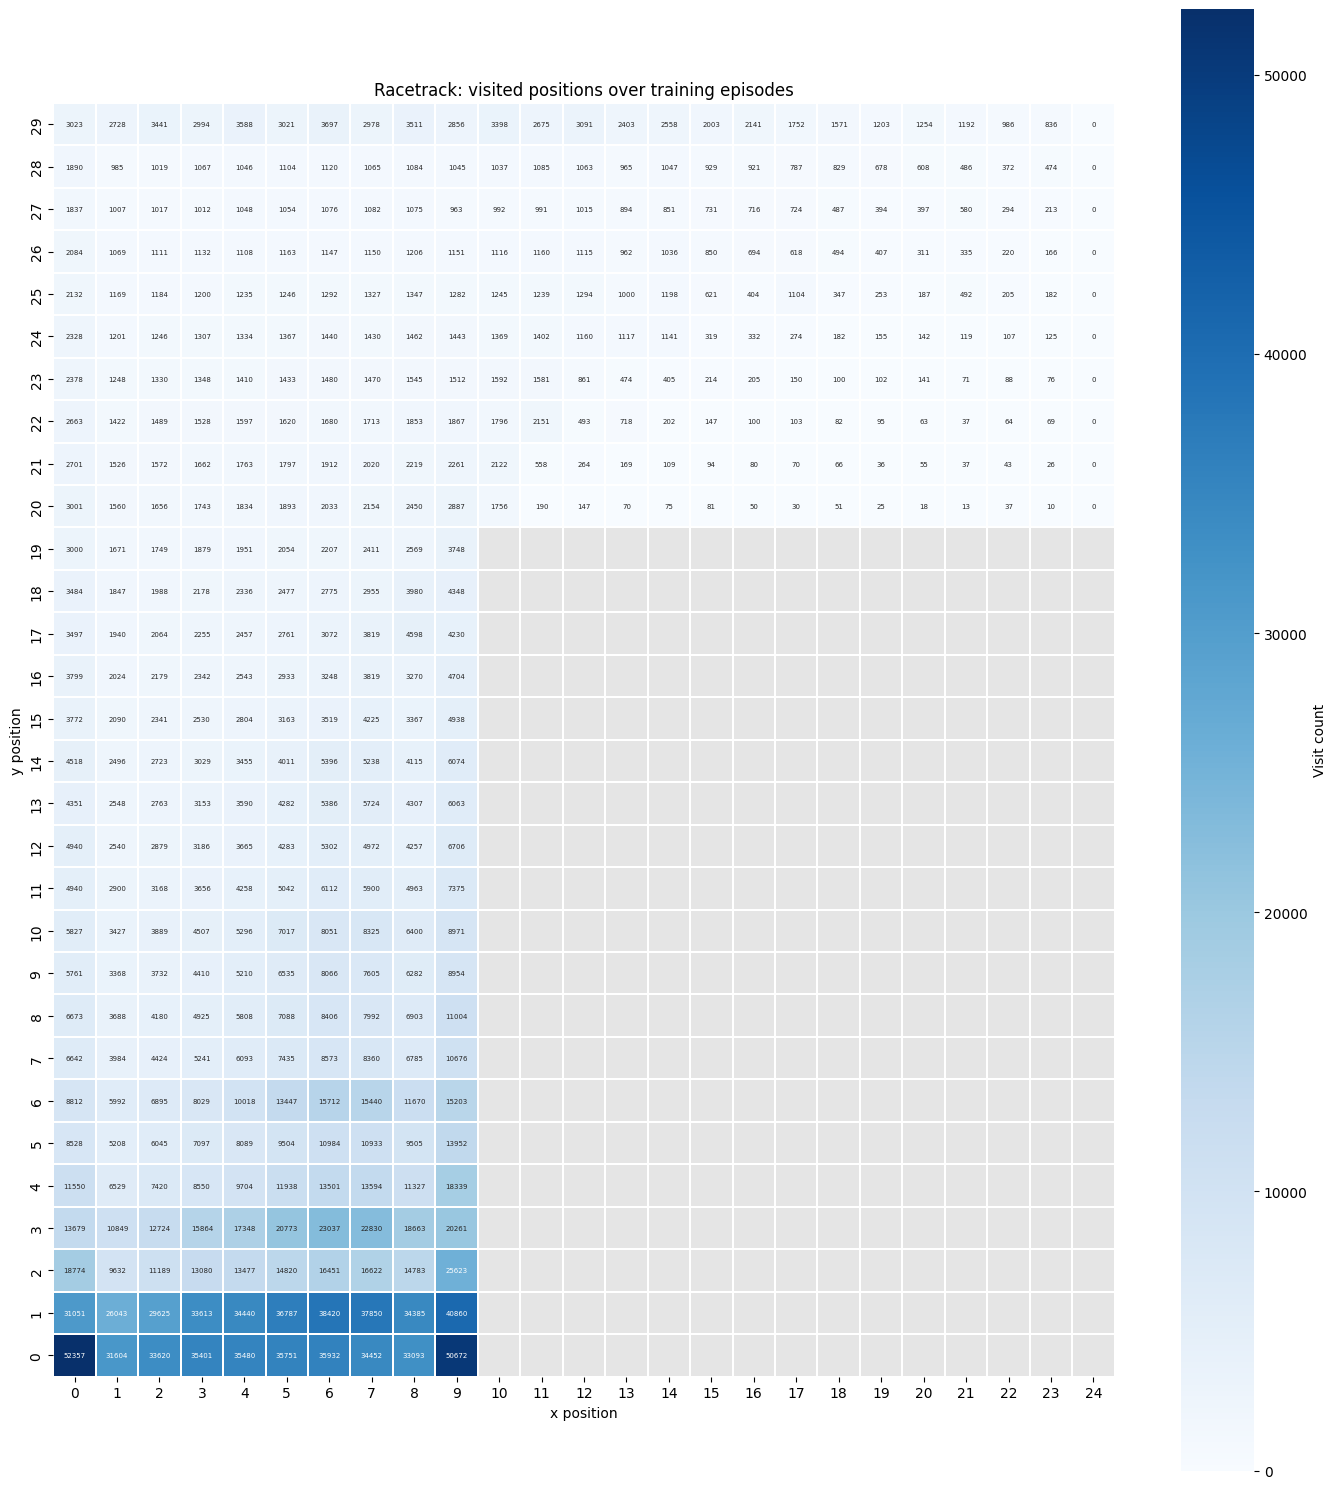

crashed: 301667
average_episode_length: 489.63533333333334
average_reward: -236.51000000000042


In [27]:
plot_heatmap(sarsa_my_reward_visits, sarsa_my_reward_track_env)
print_episode_results(sarsa_my_reward_results)

In [28]:
print_episode_results(episode_results)

crashed: 2412857
average_episode_length: 7843.678
average_reward: 557.2607007135664


# Wrecking the learning!
First we just enable the wind speed from the last lab.

In [45]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


def sarsa_with_wind_env(sarsa_class, provided_reward, training = True, episodes_max = 3000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            "state": (0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    track_env = RacetrackEnv(provided_reward, wind_speed=4, wind_chance=0.30, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.1
        elif episodes >= episodes_max*0.6:
            epsilon = 0.3
        elif episodes >= episodes_max*0.3:
            epsilon = 0.5
            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        # Reset environment and get initial state
        obs, info = track_env.reset()
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        
        # 2. Choose the initial action a for the episode
        action = agent.pi(state, epsilon)
        
        # Initialize agent's internal state/action trackers
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward
            
            next_x, next_y = track_env.pos
            next_vx, next_vy = track_env.vel
            next_state = (next_x, next_y, next_vx, next_vy)
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0
                
            step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
            action = next_action
            x, y, vx, vy = next_x, next_y, next_vx, next_vy
    
        # Record metrics at the end of the episode
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env


In [46]:
wind_sarsa_my_reward_agent, wind_sarsa_my_reward_visits, wind_sarsa_my_reward_results, wind_sarsa_my_reward_track_env = sarsa_with_wind_env(agent_expected_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Episode 2000
Episode 2100
Episode 2200
Episode 2300
Episode 2400
Episode 2500
Episode 2600
Episode 2700
Episode 2800
Episode 2900
Training finished!


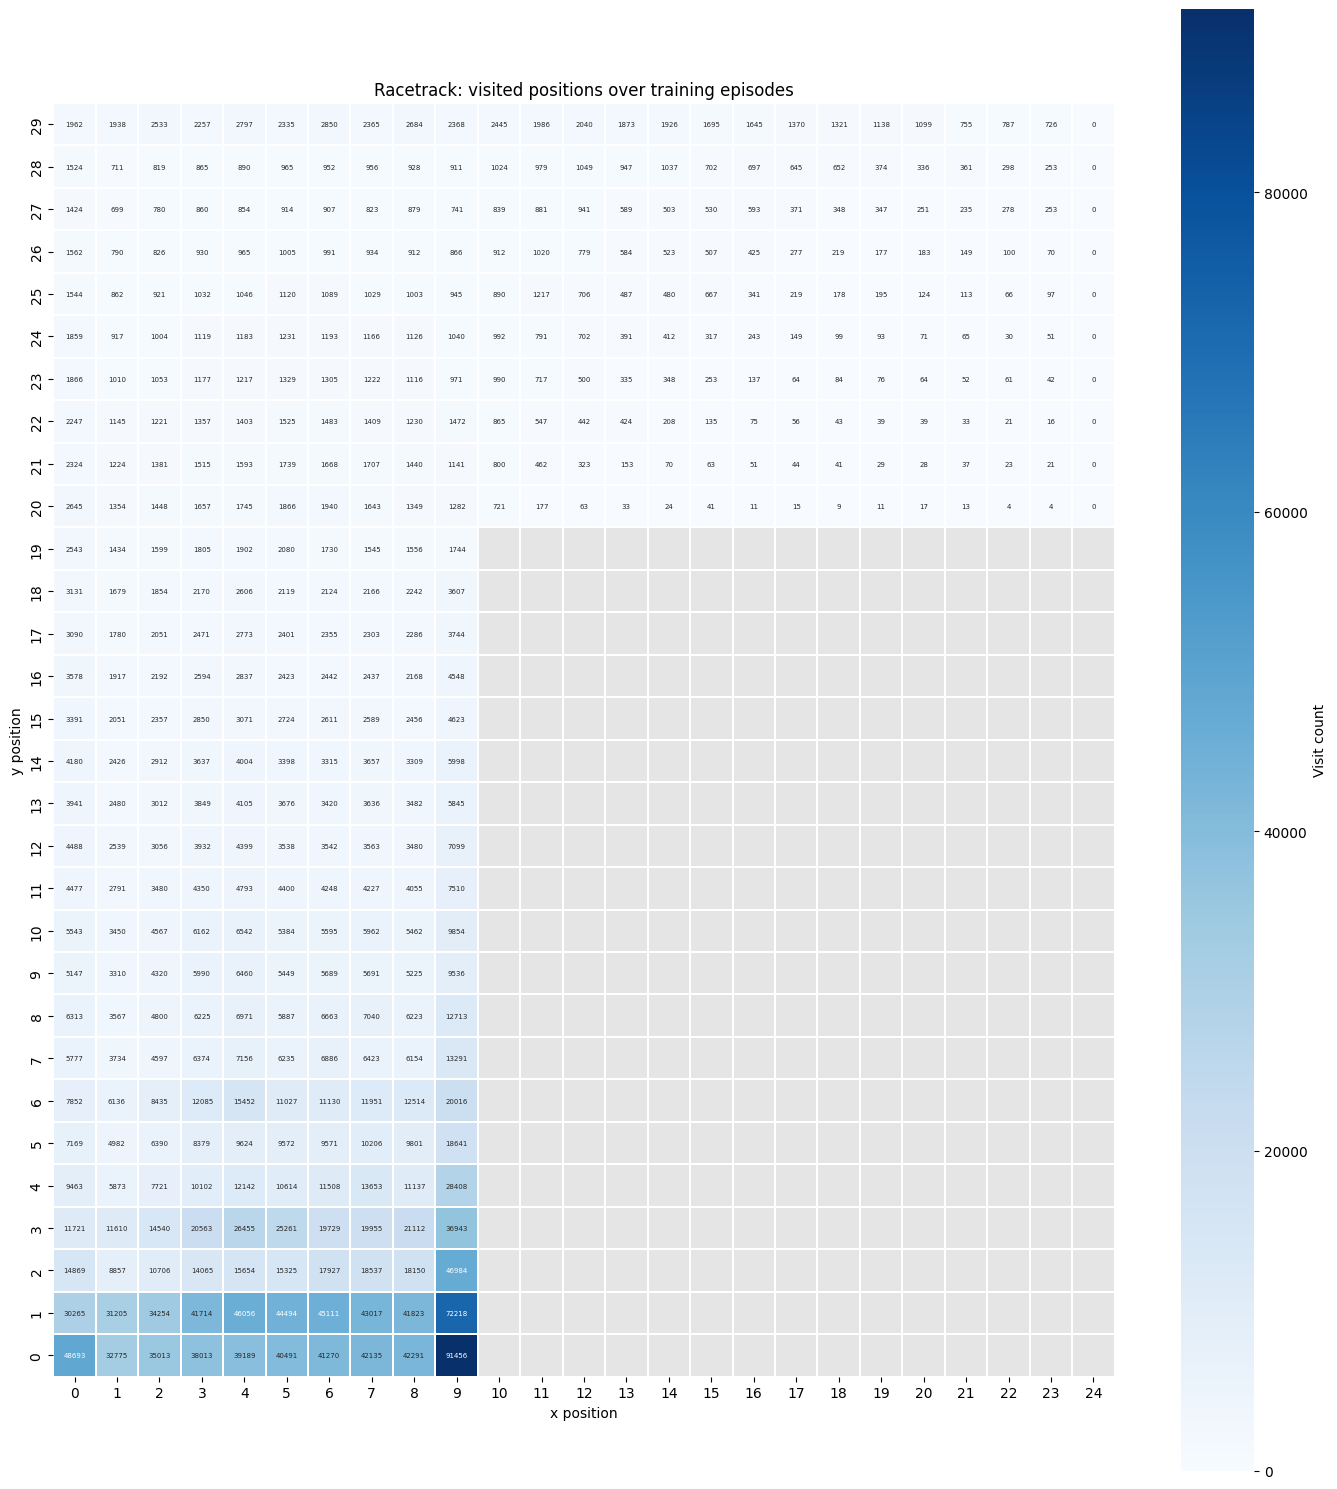

crashed: 405351
average_episode_length: 776.223
average_reward: -389.79210000000046


In [47]:
plot_heatmap(wind_sarsa_my_reward_visits, wind_sarsa_my_reward_track_env)
print_episode_results(wind_sarsa_my_reward_results)

We can then add the ability for the environment to share the if the wind would blow in the next iteration.

In [33]:
import numpy as np
class agent_expected_wind_sarsa:
    '''A class to manage the Expected SARSA agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying hyperparameters and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]
        # Epsilon of the policy being followed, updated every time pi() is called
        self.epsilon = config.get("epsilon", 0.0)

    def get_probabilities(self, state, epsilon):

        n_actions = self.config.get("n_actions", 9)
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        for ba in best_actions:
            probs[ba] += (1.0 - epsilon) / len(best_actions)
            
        return probs

    def update_Q(self, step_data, done):
        """
        Performs the Expected SARSA step-by-step update.
        step_data is stored as (next_x, next_y, next_vx, next_vy, wind_incoming, next_action, reward)
        """
        state_prime = step_data[:5]
        action_prime = step_data[5]
        reward = step_data[6]
        
        state_action_pair = (self.current_state, self.current_action)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]
        n_actions = self.config.get("n_actions", 9)

        q_map_value = self.q_map.get(state_action_pair, 0.0)
        
        if done:
            expected_next_q = 0.0
        else:
            probs = self.get_probabilities(state_prime, self.epsilon)
            next_action_values = [self.q_map.get((state_prime, a), 0.0) for a in range(n_actions)]
            expected_next_q = np.sum(probs * np.array(next_action_values))
        
        target = reward + y_discount * expected_next_q
        self.q_map[state_action_pair] = q_map_value + alpha * (target - q_map_value)
        
        self.current_state = state_prime
        self.current_action = action_prime

    def pi(self, state, epsilon):
        """
        Selects an action using the epsilon-greedy probability distribution.
        """
        self.epsilon = epsilon
        n_actions = self.config.get("n_actions", 9)
        probs = self.get_probabilities(state, epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [50]:
def sarsa_with_wind_env(sarsa_class, provided_reward, training = True, episodes_max = 3000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            # Updated initial state to include wind status (e.g., 5 elements)
            "state": (0, 0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    
    # Pass provided_reward into your RacetrackEnv constructor
    track_env = RacetrackEnv(provided_reward, wind_speed=4, wind_chance=0.30, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.1
        elif episodes >= episodes_max*0.6:
            epsilon = 0.3
        elif episodes >= episodes_max*0.3:
            epsilon = 0.5
            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        obs, info = track_env.reset()
        x, y, vx, vy, wind_app = obs
        state = (x, y, vx, vy, int(wind_app))
        
        action = agent.pi(state, epsilon)
        
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward

            # We now use the wind_incoming flag to help the agent adjust according ly
            next_x, next_y, next_vx, next_vy, next_wind_app = observation
            next_state = (next_x, next_y, next_vx, next_vy, int(next_wind_app))
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0
                
            step_data = (next_x, next_y, next_vx, next_vy, int(next_wind_app), next_action, reward)
            
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
                
            action = next_action
            x, y, vx, vy, wind_app = next_x, next_y, next_vx, next_vy, next_wind_app
        
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env

In [51]:
wind_sarsa_new_context_agent, wind_sarsa_new_context_visits, wind_sarsa_new_context_results, wind_sarsa_new_context_track_env = sarsa_with_wind_env(agent_expected_wind_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Episode 2000
Episode 2100
Episode 2200
Episode 2300
Episode 2400
Episode 2500
Episode 2600
Episode 2700
Episode 2800
Episode 2900
Training finished!


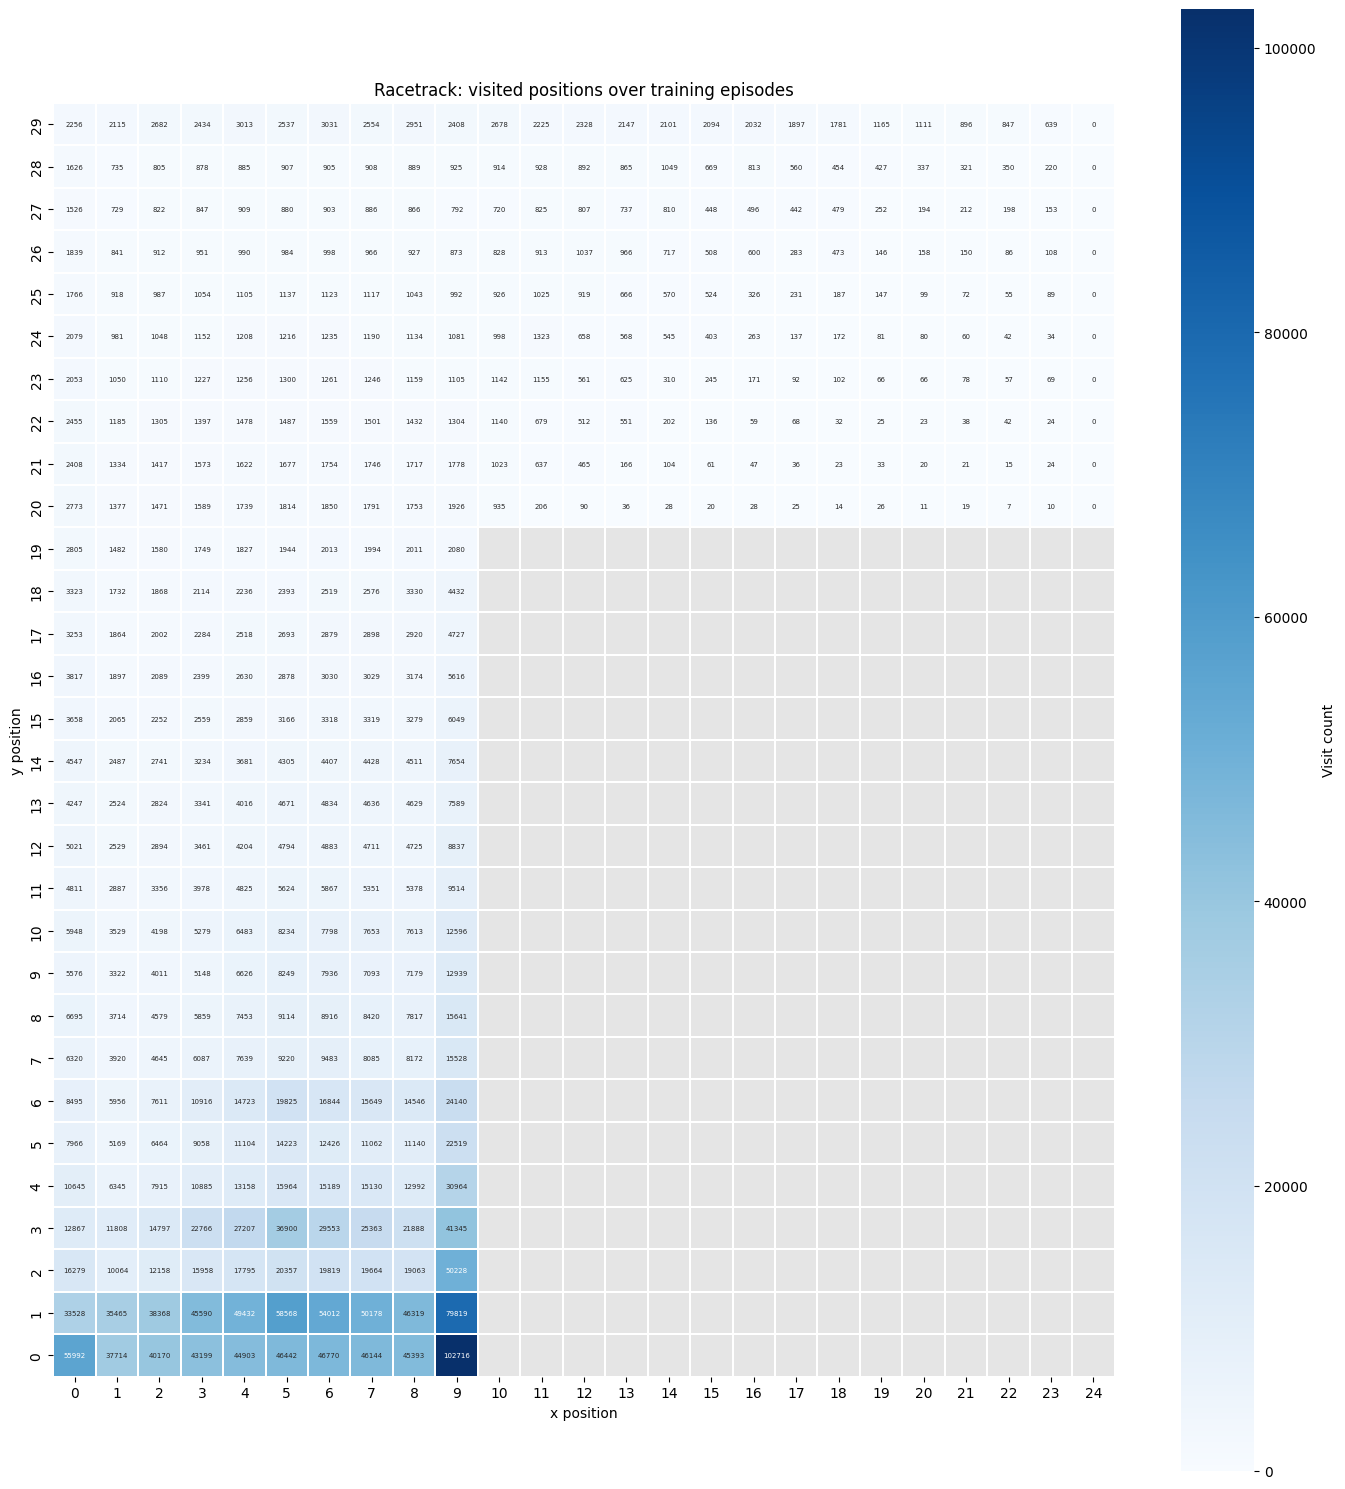

crashed: 461961
average_episode_length: 887.314
average_reward: -440.1946333333345


In [52]:
plot_heatmap(wind_sarsa_new_context_visits, wind_sarsa_new_context_track_env)
print_episode_results(wind_sarsa_new_context_results)

In [48]:
def sarsa_with_no_decay_env(sarsa_class, provided_reward, episodes_max = 3000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            # Updated initial state to include wind status
            "state": (0, 0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    
    # Pass provided_reward into your RacetrackEnv constructor
    track_env = RacetrackEnv(provided_reward, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.9
    
    while episodes != episodes_max:            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        obs, info = track_env.reset()
        x, y, vx, vy, wind_app = obs
        state = (x, y, vx, vy, int(wind_app))
        
        action = agent.pi(state, epsilon)
        
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward

            # We now use the wind_incoming flag to help the agent adjust accordingly
            next_x, next_y, next_vx, next_vy, wind_incoming = observation
            next_state = (next_x, next_y, next_vx, next_vy, int(wind_incoming))
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0
                
            step_data = (next_x, next_y, next_vx, next_vy, wind_incoming, next_action, reward)
            
            
            agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
                
            action = next_action
            x, y, vx, vy, wind_app = next_x, next_y, next_vx, next_vy, wind_incoming
        
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env

In [49]:
no_decay_sarsa_agent, no_decay_sarsa_visits, no_decay_sarsa_results, no_decay_sarsa_track_env = sarsa_with_wind_env(agent_expected_wind_sarsa, False)

Episode 0


IndexError: tuple index out of range

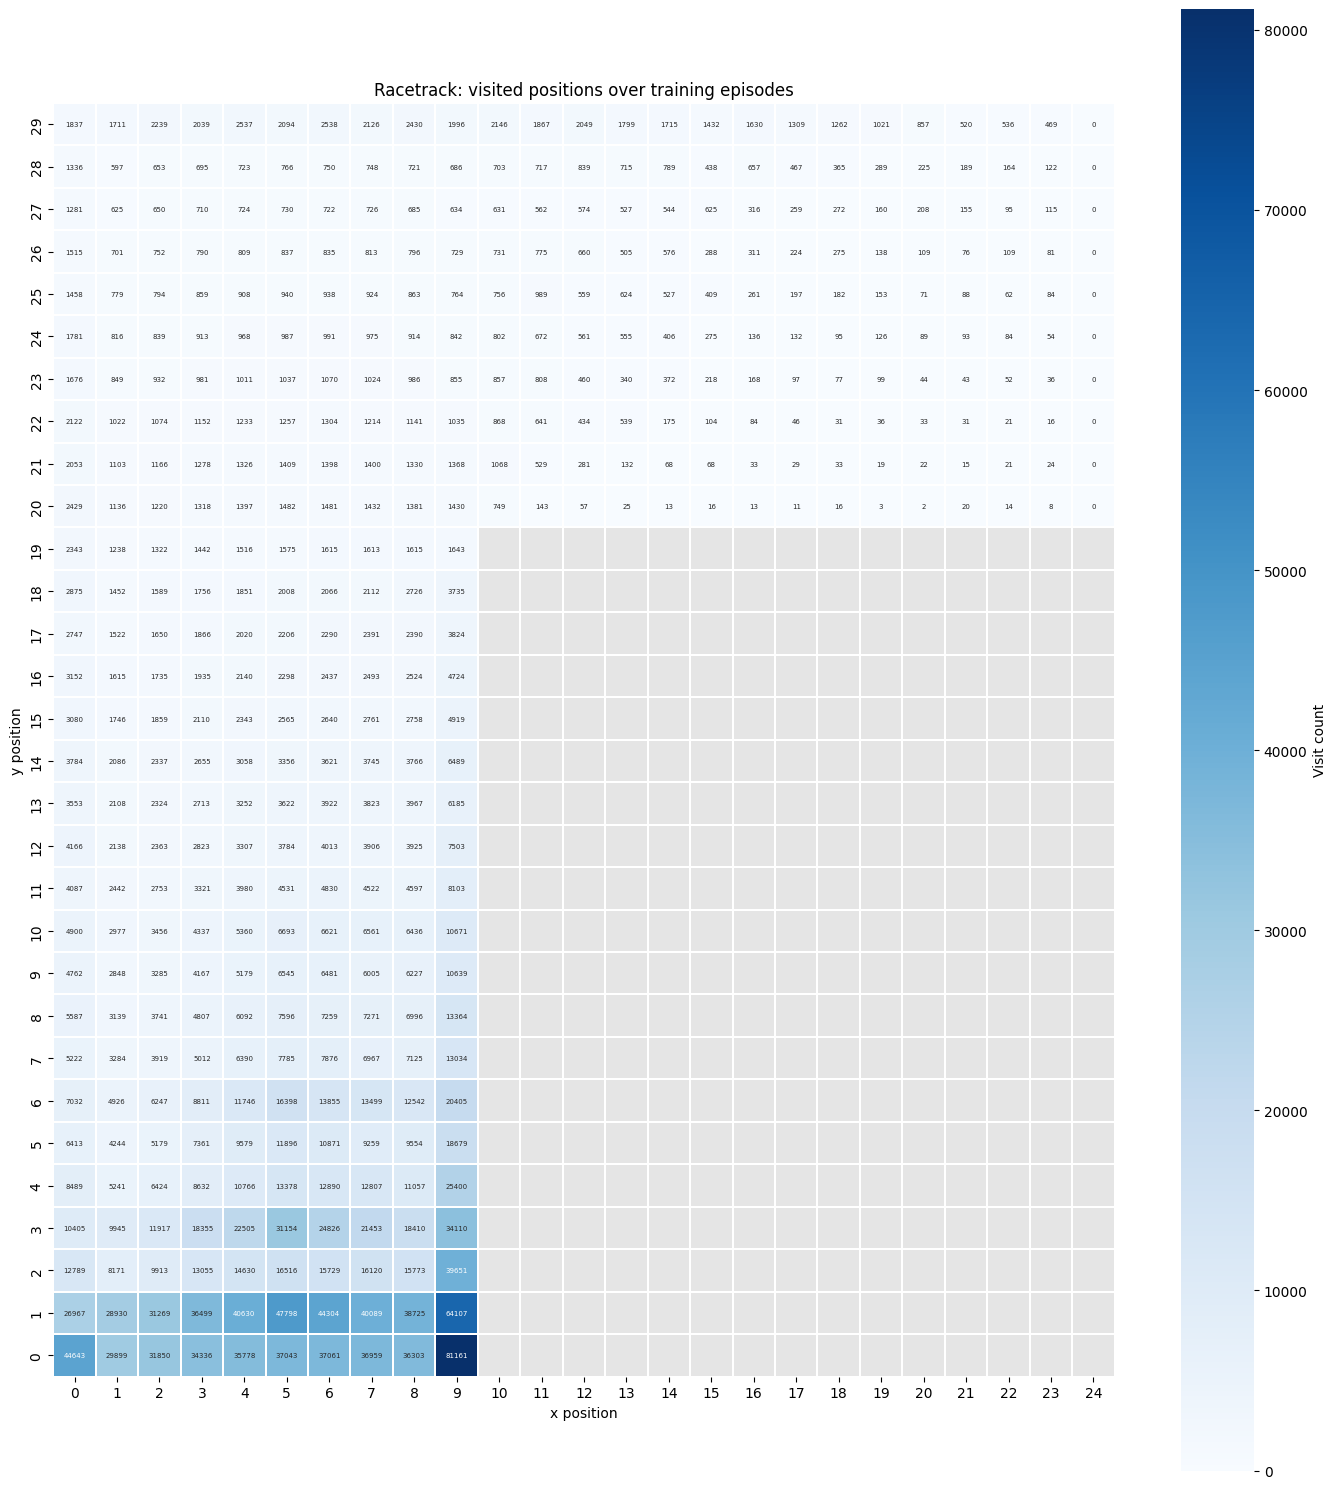

crashed: 377216
average_episode_length: 1087.3565
average_reward: -539.6125499999996


In [39]:
plot_heatmap(no_decay_sarsa_visits, no_decay_sarsa_track_env)
print_episode_results(no_decay_sarsa_results)

# Comparing Monte Carlo, SARSA & Expected SARSA
Each algorithm is trained for 3000 episodes with no wind, once with the provided reward and once with my reward. All six runs are trained at the same time in separate processes.

In [40]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from time import time
# Had Claude generate this cell and below 
comparison_episodes = 5000

# (name, training function, agent class, use provided reward)
comparison_jobs = [
    # ("Monte Carlo - provided reward",    monte_carlo_env, agent_monte_carlo,    True),
    ("Monte Carlo - my reward",          monte_carlo_env, agent_monte_carlo,    False),
    # ("SARSA - provided reward",          sarsa_env,       agent_sarsa,          True),
    ("SARSA - my reward",                sarsa_env,       agent_sarsa,          False),
    # ("Expected SARSA - provided reward", sarsa_env,       agent_expected_sarsa, True),
    ("Expected SARSA - my reward",       sarsa_env,       agent_expected_sarsa, False),
]

def run_comparison_job(job):
    name, env_function, agent_class, provided_reward = job
    start = time()
    result = env_function(agent_class, provided_reward, episodes_max=comparison_episodes, label=f"[{name}] ")
    return name, result, time() - start

comparison_results = {}
# fork lets the worker processes use the classes and functions defined in this notebook
with ProcessPoolExecutor(max_workers=len(comparison_jobs), mp_context=mp.get_context("fork")) as executor:
    futures = [executor.submit(run_comparison_job, job) for job in comparison_jobs]
    for future in as_completed(futures):
        name, result, elapsed = future.result()
        comparison_results[name] = result
        print(f"===== {name} finished in {elapsed/60:.1f} minutes =====")

[SARSA - my reward] Episode 0[Monte Carlo - my reward] Episode 0[Expected SARSA - my reward] Episode 0


[SARSA - my reward] Episode 100
[Monte Carlo - my reward] Episode 100
[Expected SARSA - my reward] Episode 100
[Monte Carlo - my reward] Episode 200
[SARSA - my reward] Episode 200
[Expected SARSA - my reward] Episode 200
[Monte Carlo - my reward] Episode 300
[SARSA - my reward] Episode 300
[Monte Carlo - my reward] Episode 400
[Expected SARSA - my reward] Episode 300
[Monte Carlo - my reward] Episode 500
[Monte Carlo - my reward] Episode 600
[SARSA - my reward] Episode 400
[Monte Carlo - my reward] Episode 700
[Expected SARSA - my reward] Episode 400
[Monte Carlo - my reward] Episode 800
[SARSA - my reward] Episode 500
[Monte Carlo - my reward] Episode 900
[Expected SARSA - my reward] Episode 500
[Monte Carlo - my reward] Episode 1000
[Monte Carlo - my reward] Episode 1100
[SARSA - my reward] Episode 600
[Monte Carlo - my reward] Episode 1200
[Expected SARSA - my reward] Episode 60

===== Monte Carlo - my reward =====


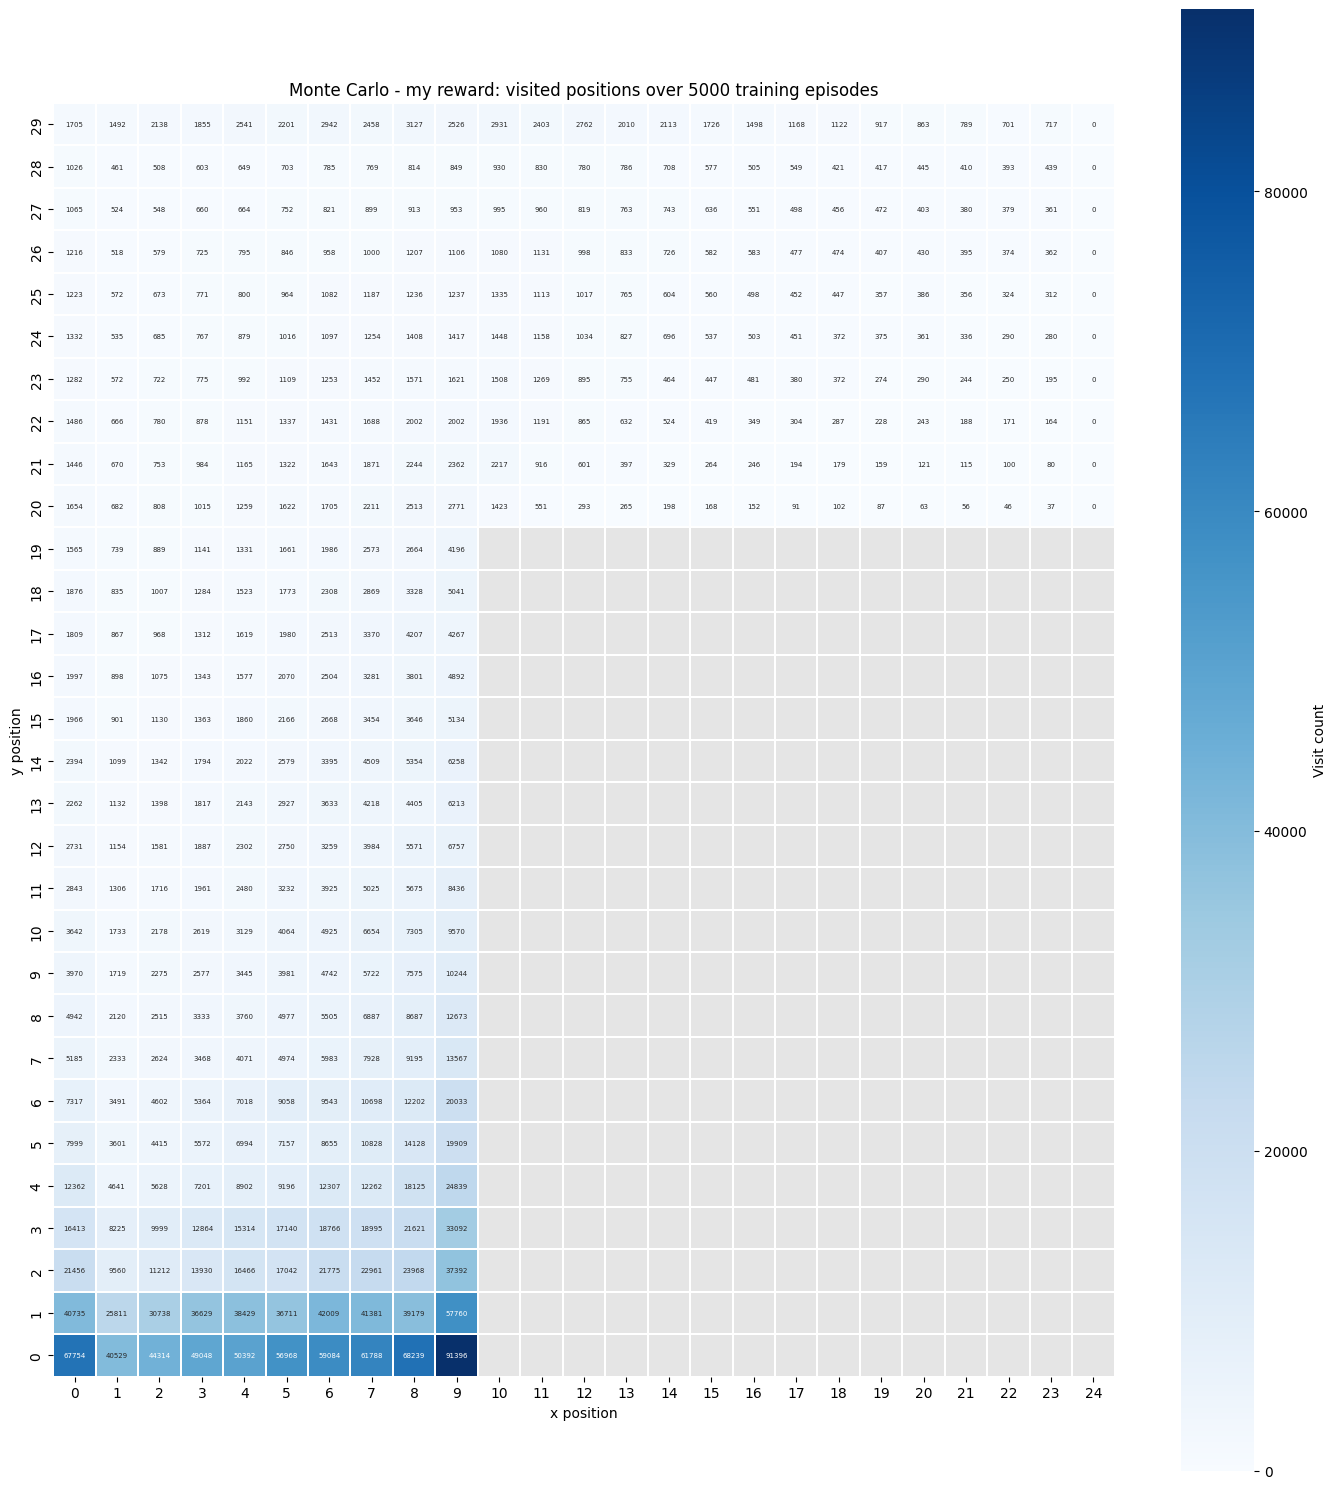

crashed: 339648
average_episode_length: 460.0554
average_reward: -207.46046000000018
Total Number of steps: 2300277
===== SARSA - my reward =====


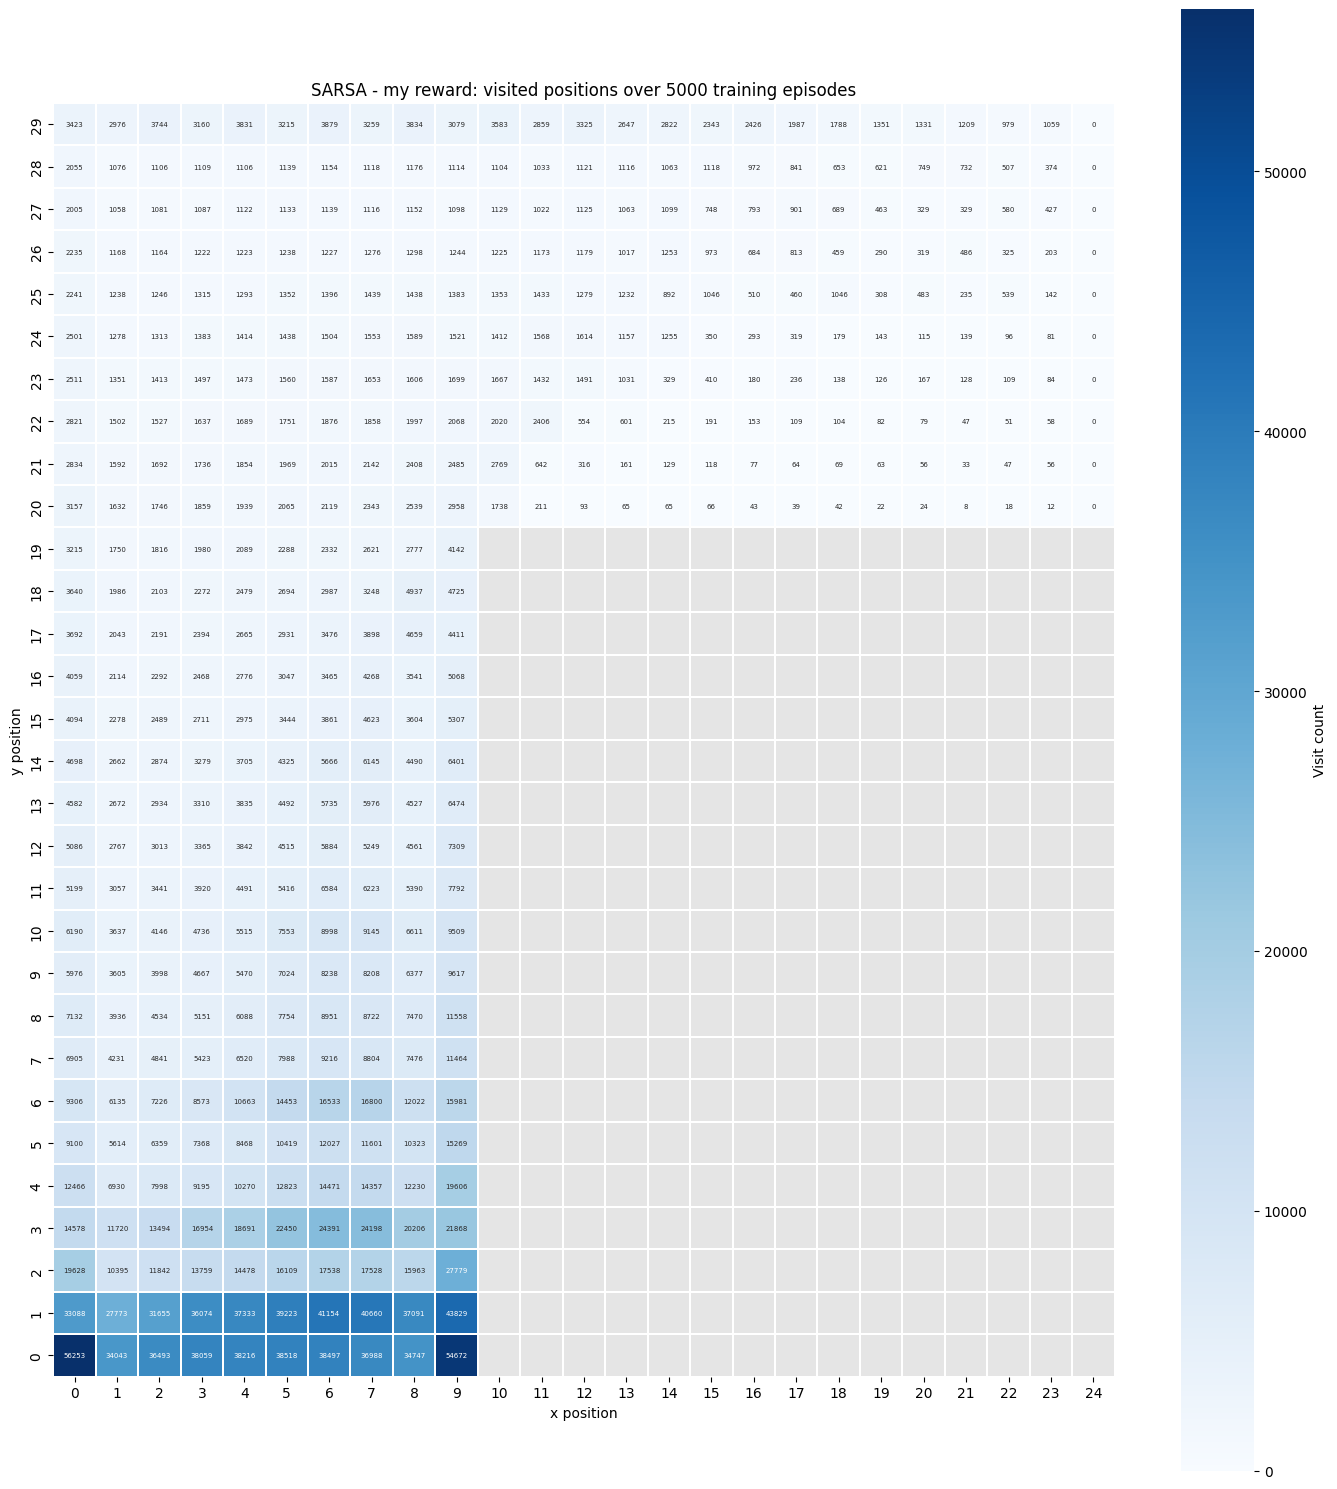

crashed: 322897
average_episode_length: 472.4564
average_reward: -227.25795999999897
Total Number of steps: 2362282
===== Expected SARSA - my reward =====


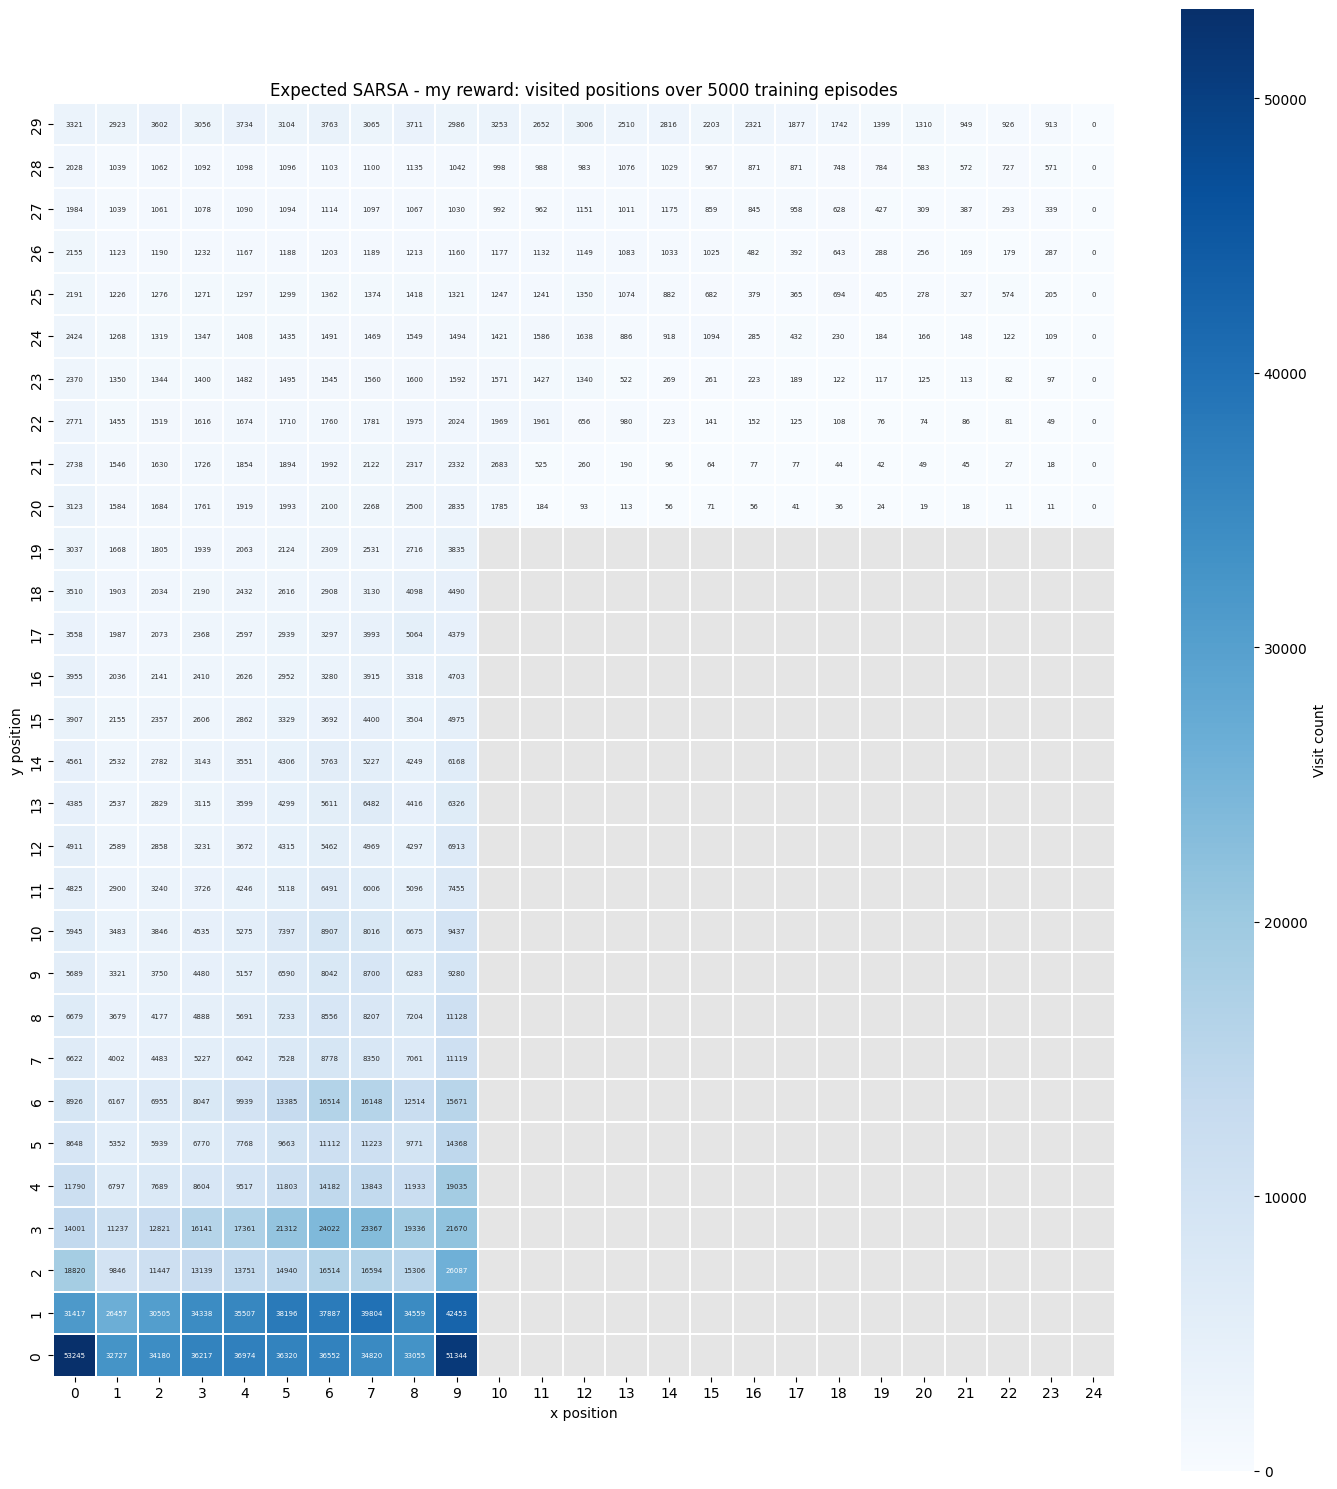

crashed: 307921
average_episode_length: 451.4974
average_reward: -217.1499199999997
Total Number of steps: 2257487


In [41]:
for name, _, _, _ in comparison_jobs:
    agent, visits, results, track_env = comparison_results[name]
    print(f"===== {name} =====")
    plot_heatmap(visits, track_env, title=f"{name}: visited positions over {comparison_episodes} training episodes")
    print_episode_results(results)
    print(f"Total Number of steps: {sum(results['list_of_steps'])}")